In [1]:
from datetime import datetime
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import skewnorm, skew, norm

In [2]:
# df = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/data_temp_senseca/pro_line_log_20261110154337_0.csv", sep=";")
df = pd.read_csv("/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/data_temp_senseca/pro_line_log_20261110154337_0.csv", sep=";")
df["date"] = pd.to_datetime(df["date"])
df = df.set_index('date')

In [3]:
# df

In [4]:
# nur die Werte nehmen, die am nächsten an der 10-Minuten-Marke sind

df.index = df.index.floor("1min")
df = df[df.index == df.index.floor('10min')]
# df_res10 = df.resample('10min').mean()

In [5]:
# df

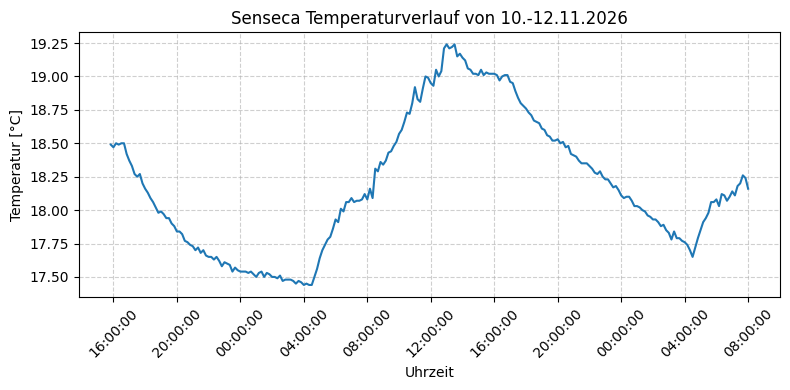

In [6]:
# Diagramm zeichnen
plt.figure(figsize=(8, 4))
plt.plot(df.index, df["temp"])

# Achsen und Layout formatieren
plt.title("Senseca Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()


In [7]:
df_picos = pd.read_csv("/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/src/data/data_pico2-7_1011_1211.csv", sep=",")
df_picos["_time"] = pd.to_datetime(df_picos["_time"], format="mixed")

In [8]:
# df_picos

In [9]:
df_picos = df_picos[["_time", "_value", "DEVICE_ID"]]
df_picos.columns = ['date', 'temp', 'id']
df_picos = df_picos.set_index('date')
df_picos.index = df_picos.index.tz_localize(None)

In [10]:
# df_picos

In [11]:
df_pico2 = df_picos[df_picos["id"] == "pico_2"][2:-15]
df_pico3 = df_picos[df_picos["id"] == "pico_3"][2:-15]
df_pico4 = df_picos[df_picos["id"] == "pico_4"][2:-15]
df_pico5 = df_picos[df_picos["id"] == "pico_5"][2:-14]
df_pico6 = df_picos[df_picos["id"] == "pico_6"][2:-15]
df_pico7 = df_picos[df_picos["id"] == "pico_7"][2:-15]

In [12]:
picos_dfs = [df_pico2, df_pico3, df_pico4, df_pico5, df_pico6, df_pico7]

In [13]:
picos_dfs_names = ["Pico_2", "Pico_3", "Pico_4", "Pico_5", "Pico_6", "Pico_7"]

In [14]:
dfs = [df_pico2, df_pico3, df_pico4, df_pico5, df_pico6, df_pico7, df]

In [15]:
dfs_names = ["Pico_2", "Pico_3", "Pico_4", "Pico_5", "Pico_6", "Pico_7", "Senseca"]

In [16]:
len(df_pico2), len(df_pico3), len(df_pico4), len(df_pico5), len(df_pico6), len(df_pico7), 

(242, 242, 242, 242, 242, 242)

In [17]:
summary = ergebnis = pd.concat(dfs, axis=1)
summary = summary.drop(columns=['id'])
summary.columns = dfs_names

In [18]:
# for df_pico, name in zip(picos_dfs, picos_dfs_names):
#     # Diagramm zeichnen
#     plt.figure(figsize=(8, 4))
#     plt.plot(df_pico.index, df_pico["temp"])

#     # Achsen und Layout formatieren
#     plt.title(name + " Temperaturverlauf von 10.-12.11.2026")
#     plt.xlabel("Uhrzeit")
#     plt.ylabel("Temperatur [°C]")
#     plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
#     plt.xticks(rotation=45)
#     plt.grid(True, linestyle="--", alpha=0.6)
#     plt.tight_layout()

#     plt.show()

In [19]:
diff_lst = []
for df_pico, name in zip(picos_dfs, picos_dfs_names):
    diff = df_pico["temp"].values - df["temp"].values
    diff_lst.append(diff)

In [20]:
summary_diff = pd.DataFrame(
    data=zip(*diff_lst),
    index=df_pico2.index,
    columns=picos_dfs_names
)

In [21]:
# for diff, name in zip(diff_lst, picos_dfs_names):
#     # Diagramm zeichnen
#     plt.figure(figsize=(8, 4))
#     plt.plot(df.index, diff)

#     # Achsen und Layout formatieren
#     plt.title("Differenz zwischen den Messungen von " + name + " und Senseca")
#     plt.xlabel("Uhrzeit")
#     plt.ylabel("Temperatur [°C]")
#     plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
#     plt.xticks(rotation=45)
#     plt.grid(True, linestyle="--", alpha=0.6)
#     plt.tight_layout()

#     plt.show()

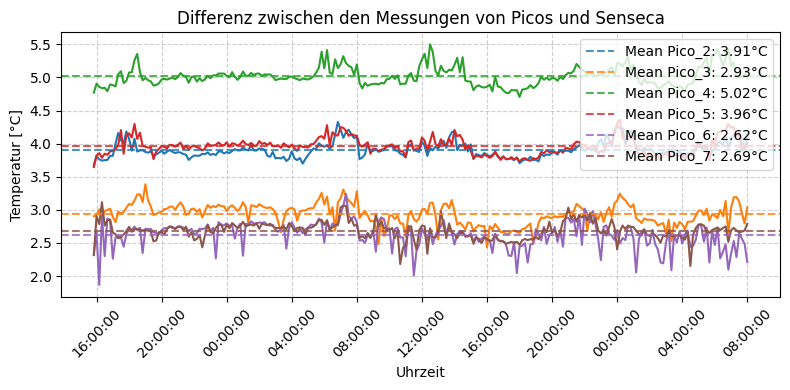

In [22]:
# Diagramm zeichnen
plt.figure(figsize=(8, 4))
plt.plot(summary_diff.index, summary_diff)#, label=summary_diff.columns)

linien = plt.gca().get_lines()

for col, linie in zip(summary_diff.columns, linien):
    mean = summary_diff[col].mean()
    farbe = linie.get_color()
    
    plt.axhline(
        y=mean, 
        color=farbe, 
        linestyle="--", 
        alpha=0.8, 
        label=f"Mean {col}: {mean:.2f}°C" # Optional: Direkt in die Legende aufnehmen
    )

# Achsen und Layout formatieren
plt.title("Differenz zwischen den Messungen von Picos und Senseca")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(loc='upper right')

plt.show()

In [23]:
picos_mean = [x.mean().round(2) for x in diff_lst]
picos_std = [x.std(ddof=1).round(2) for x in diff_lst]

In [24]:
print("Mittelwerte und Standardabweichung der Differnez zwischen Pico und Senseca:\n")
for mean, std, name in zip(picos_mean, picos_std, picos_dfs_names):
    print(name + ":    Mean " + str(mean) + "    Std " + str(std))

Mittelwerte und Standardabweichung der Differnez zwischen Pico und Senseca:

Pico_2:    Mean 3.91    Std 0.12
Pico_3:    Mean 2.93    Std 0.16
Pico_4:    Mean 5.02    Std 0.14
Pico_5:    Mean 3.96    Std 0.13
Pico_6:    Mean 2.62    Std 0.2
Pico_7:    Mean 2.69    Std 0.13


In [25]:
# diff_lst = []
# for df_pico_comp in picos_dfs:
#     diff_lst_comp = []
#     for df_pico, name in zip(picos_dfs, picos_dfs_names):
#         diff = df_pico["temp"].values - df_pico_comp["temp"].values
#         diff_lst_comp.append(diff)
#     diff_lst.append(diff_lst_comp)

In [26]:
# print("Mittelwerte und Standardabweichung der Differnez zwischen...")
# for i in range(len(diff_lst)):
#     print("\nPico_" + str(i+2) + " und...")
#     for diff, name in zip(diff_lst[i], picos_dfs_names):
#         print(name + ":    Mean " + str(diff.mean().round(2)) + "    Std " + str(diff.std().round(2)))

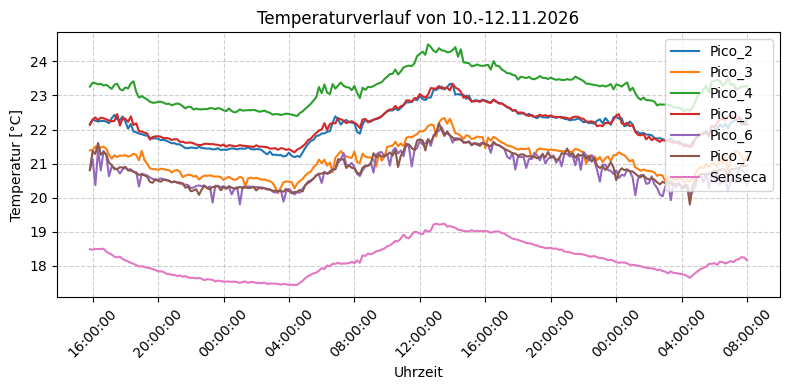

In [27]:
# Diagramm zeichnen
plt.figure(figsize=(8, 4))
plt.plot(summary.index, summary)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(summary.columns, loc='upper right')

plt.show()

In [28]:
# mean = []
# for pico in picos_dfs:
#     mean_ = []
#     for pico_ in picos_dfs:
#         diff = pico_["temp"].values - pico["temp"].values
#         mean_.append(diff.mean().round(2))
#     mean.append(mean_)

In [29]:
# np.array(mean)

In [30]:
# std = []
# for pico in picos_dfs:
#     std_ = []
#     for pico_ in picos_dfs:
#         diff = pico_["temp"].values - pico["temp"].values
#         std_.append(diff.std().round(2))
#     std.append(std_)

In [31]:
# np.array(std)

In [32]:
# for i in range(6):
#     # 1. Deine Liste mit Messwerten / Zahlen
#     daten = diff_lst[i]

#     # 2. Mittelwert (mu) und Standardabweichung (std) aus den Daten berechnen
#     # (ddof=1 für Stichprobe, wie besprochen)
#     mu, std = np.mean(daten), np.std(daten, ddof=1)

#     # 3. Plot vorbereiten
#     plt.figure(figsize=(8, 5))

#     # A) Histogramm der echten Daten anzeigen 
#     # density=True skaliert das Histogramm, damit die Fläche unter dem Histogramm 1 ergibt (wichtig für den Vergleich mit der Kurve)
#     count, bins, ignored = plt.hist(daten, bins=6, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Messdaten')

#     # B) X-Werte für die glatte Glockenkurve generieren
#     xmin, xmax = plt.xlim()
#     x = np.linspace(xmin, xmax, 100)

#     # C) Wahrscheinlichkeitsdichte (PDF - Probability Density Function) berechnen
#     p = norm.pdf(x, mu, std)

#     # D) Die theoretische Normalverteilungskurve einzeichnen
#     plt.plot(x, p, 'r-', linewidth=2, label=f'Normalverteilung\n(MW: {mu:.2f}, Std: {std:.2f})')

#     plt.ylim(0, 3.99)

#     # Layout und Beschriftung
#     plt.title(f"Normalverteilung der Daten von Pico_{i+2}")
#     plt.xlabel("Wert")
#     plt.ylabel("Dichte")
#     plt.legend(loc='upper right')
#     plt.grid(True, linestyle="--", alpha=0.5)

#     plt.tight_layout()
#     plt.show()

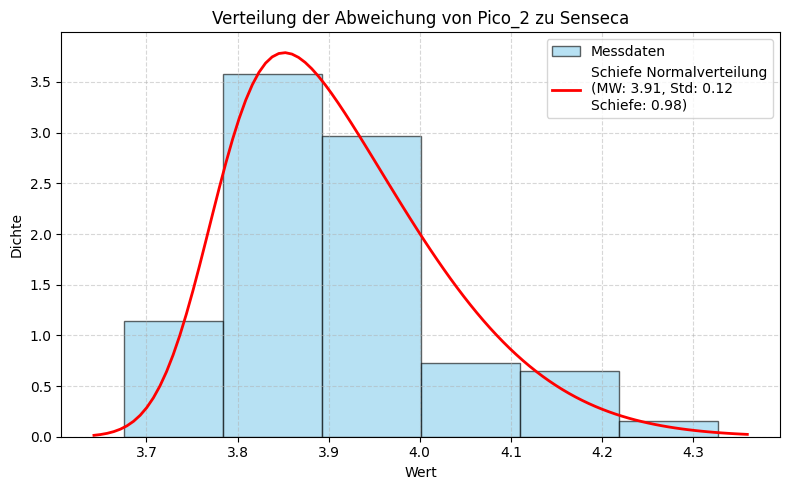

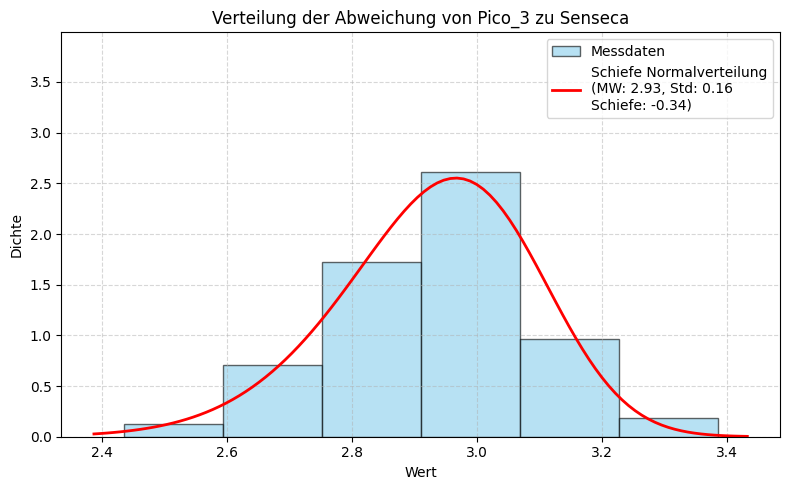

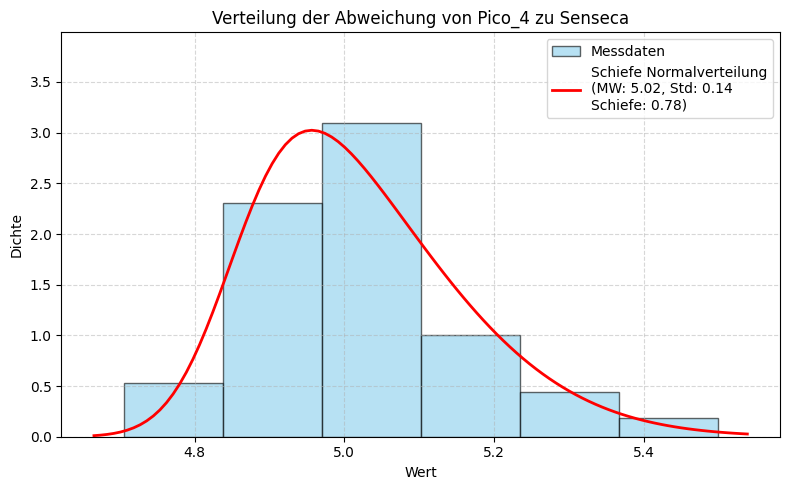

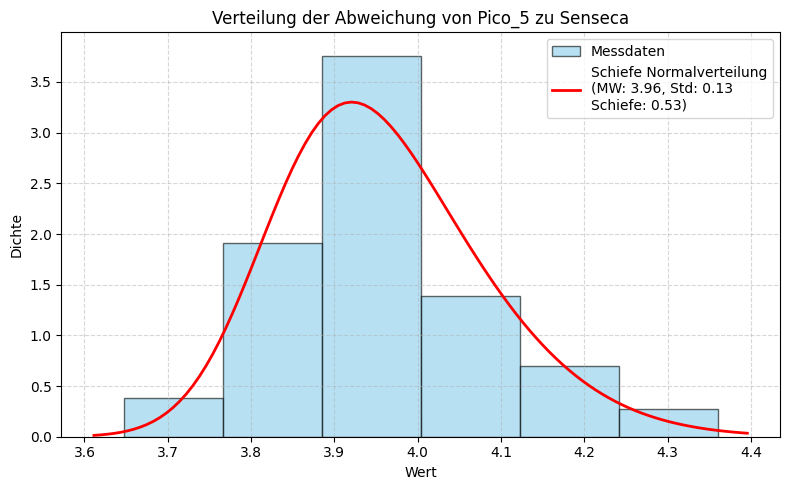

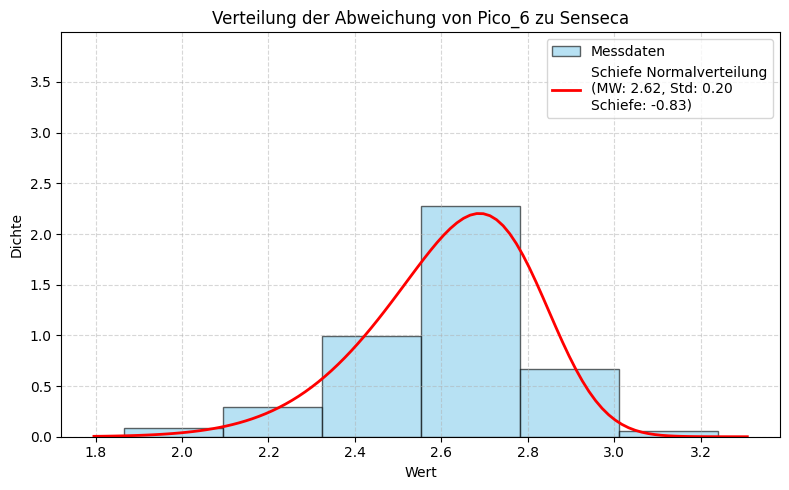

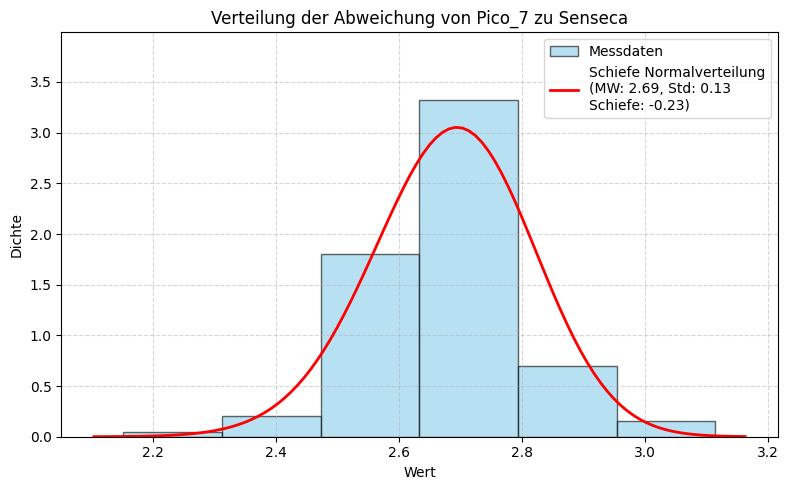

In [80]:
for i in range(6):
    # Beispiel-Daten (mit einer leichten rechtsschiefen Tendenz durch einen höheren Wert)
    daten = diff_lst[i]

    # 1. Schiefe der Daten berechnen
    daten_schiefe = skew(daten)

    # 2. Schiefe Normalverteilung an die Daten anpassen (skewnorm)
    # skewnorm.fit(daten) schätzt die Parameter (Form/Schiefe, Mittelwert, Streuung)
    params = skewnorm.fit(daten) 

    # Mittelwert (mu) und Standardabweichung (std) aus den Daten berechnen
    # (ddof=1 für Stichprobe)
    mu, std = np.mean(daten), np.std(daten, ddof=1)

    # 3. Plot vorbereiten
    plt.figure(figsize=(8, 5))

    # Histogramm der echten Daten
    plt.hist(daten, bins=6, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Messdaten')

    # X-Werte für die Kurve generieren
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)

    # Wahrscheinlichkeitsdichte der schiefen Normalverteilung berechnen
    p = skewnorm.pdf(x, *params)

    # Kurve einzeichnen und Schiefe im Label angeben
    plt.plot(x, p, 'r-', linewidth=2, label=f'Schiefe Normalverteilung\n(MW: {mu:.2f}, Std: {std:.2f}\nSchiefe: {daten_schiefe:.2f})')

    plt.ylim(0, 3.99)

    # Layout und Beschriftung
    plt.title(f"Verteilung der Abweichung von Pico_{i+2} zu Senseca")
    plt.xlabel("Wert")
    plt.ylabel("Dichte")
    plt.legend(loc='upper right')
    plt.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

In [34]:
for col in summary.columns:
    tmin = round(min(summary[col]), 2)
    tmax = round(max(summary[col]), 2)
    print(f"{col}    min:   {tmin}    max: {tmax}")

Pico_2    min:   21.19    max: 23.34
Pico_3    min:   20.13    max: 22.34
Pico_4    min:   22.4    max: 24.5
Pico_5    min:   21.33    max: 23.35
Pico_6    min:   19.81    max: 22.07
Pico_7    min:   19.8    max: 22.18
Senseca    min:   17.44    max: 19.24


In [35]:
# Kalibrierung hier nur für diesen Temperaturbereich

In [36]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# X_sensor: Ihre Sensorwerte, y_ref: Werte des Referenzgeräts
X_sensor = summary["Pico_2"].values.reshape(-1, 1)
y_ref = summary["Senseca"].values

# Erstellen eines Modells mit Polynomen (fängt Offset, Steigung und Nicht-Linearität ab)
degree = 2  # Grad anpassen je nach Sensorverhalten
calib_model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
calib_model.fit(X_sensor, y_ref)

# Anwendung der Kalibrierfunktion auf neue Messwerte
y_kalibriert = calib_model.predict(X_sensor)

In [37]:
y_kalibriert2 = summary["Pico_2"].values - picos_mean[0]

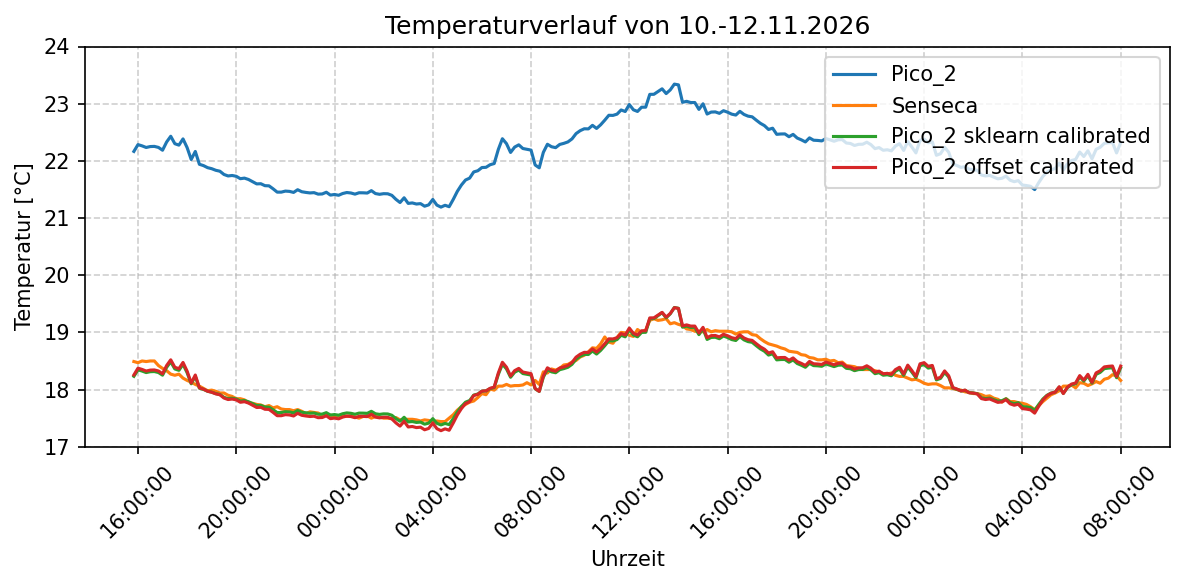

In [38]:
# Diagramm zeichnen
plt.figure(figsize=(8, 4), dpi=150)
plt.plot(summary.index, summary[["Pico_2", "Senseca"]], label=summary[["Pico_2", "Senseca"]].columns)
plt.plot(summary.index, y_kalibriert, label="Pico_2 sklearn calibrated")
plt.plot(summary.index, y_kalibriert2, label="Pico_2 offset calibrated")

plt.ylim(17, 24)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(loc='upper right')

plt.show()

In [39]:
# summary["Senseca"].to_csv(
#     '/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/data_temp_senseca/senseca.csv', 
#     index=False,          # Verhindert, dass der Zeilenindex (0, 1, 2...) als eigene Spalte gespeichert wird
#     sep=';',              # Semikolon statt Komma (oft besser für Excel in deutscher Umgebung)
#     decimal=',',      # Komma statt Punkt für Gleitkommazahlen
# )

In [40]:
# summary["Pico_2"].to_csv(
#     '/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/data_temp_senseca/pico2.csv', 
#     index=False,          # Verhindert, dass der Zeilenindex (0, 1, 2...) als eigene Spalte gespeichert wird
#     sep=';',              # Semikolon statt Komma (oft besser für Excel in deutscher Umgebung)
#     decimal=',',      # Komma statt Punkt für Gleitkommazahlen
# )

In [78]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# 3. Train/Test-Split (zeitlich geordnet, ohne Shuffle)
split = int(len(summary["Pico_2"].to_numpy()) * 0.7) # split = int(len(df) * 0.7)
# train, test = df.iloc[:split], df.iloc[split:]

X_train = summary["Pico_2"].iloc[:split].to_numpy().reshape(-1, 1) # train[["temp_sensor"]].to_numpy()
y_train = summary["Senseca"].iloc[:split].to_numpy().reshape(-1, 1) # train["temp_ref"].to_numpy()
X_test = summary["Pico_2"].iloc[split:].to_numpy().reshape(-1, 1) # test[["temp_sensor"]].to_numpy()
y_test = summary["Senseca"].iloc[split:].to_numpy().reshape(-1, 1) # test["temp_ref"].to_numpy()

# 4. Univariate lineare Regression (OLS) fitten
model = LinearRegression()
model.fit(X_train, y_train)

alpha_0 = model.intercept_
alpha_1 = model.coef_[0]
print(f"Kalibrierformel: T_kal = {alpha_0} + {alpha_1} * T_sensor")

# 5. Vorhersage & Auswertung auf Testdaten (vorher vs. nachher)
y_pred_raw = X_test # test["temp_sensor"].to_numpy()
y_pred_cal = model.predict(X_test)

print(f"Rohdaten  -> MAE: {mean_absolute_error(y_test, y_pred_raw):.4f} °C | "
      f"RMSE: {root_mean_squared_error(y_test, y_pred_raw):.4f} °C")
print(f"Kalibriert-> MAE: {mean_absolute_error(y_test, y_pred_cal):.4f} °C | "
      f"RMSE: {root_mean_squared_error(y_test, y_pred_cal):.4f} °C")

Kalibrierformel: T_kal = [-2.76818042] + [0.94936498] * T_sensor
Rohdaten  -> MAE: 3.9598 °C | RMSE: 3.9614 °C
Kalibriert-> MAE: 0.0880 °C | RMSE: 0.1296 °C


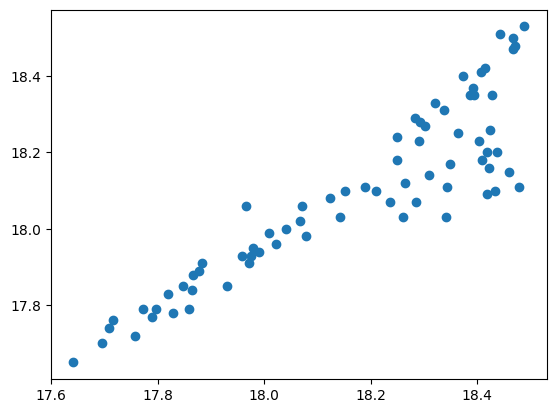

In [79]:
plt.scatter(y_pred_cal, y_test)

In [55]:
len(summary), len(summary["Senseca"])

(242, 242)

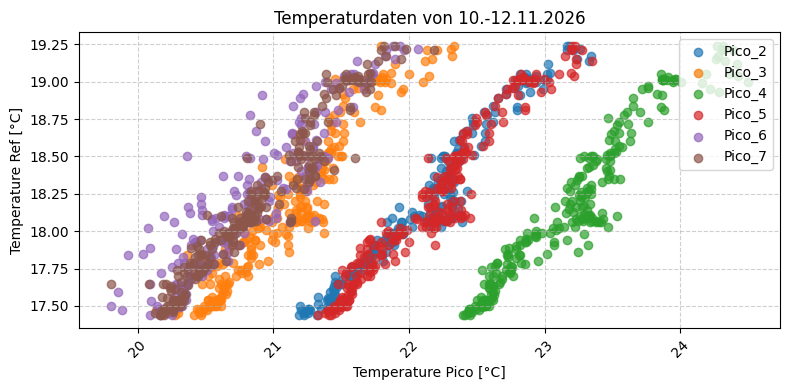

In [67]:
# Diagramm zeichnen
plt.figure(figsize=(8, 4))
for pico in picos_dfs_names:
    plt.scatter(summary[pico], summary["Senseca"], alpha=0.7)

# Achsen und Layout formatieren
plt.title("Temperaturdaten von 10.-12.11.2026")
plt.xlabel("Temperature Pico [°C]")
plt.ylabel("Temperature Ref [°C]")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(summary.columns, loc='upper right')

plt.show()